# Model Evaluation: How Good Is Our Model?

Welcome! We have learned how to fit models. Now we need to decide whether their predictions are actually useful. A model can memorize its training examples, earn impressive accuracy by ignoring a rare class, or rank examples well but make poor decisions at the chosen cutoff. **How do we recognize these problems before using the model on new data?**

---
### What We Will Cover
1. **Train, Validation, and Test Sets** — learning, choosing, and reporting
2. **Regression Metrics** — MAE, MSE, RMSE, and $R^2$
3. **Classification Metrics** — confusion matrices, accuracy, precision, recall, and F1
4. **Class Imbalance** — baselines, balanced accuracy, and ranking metrics
5. **Thresholds** — turning probabilities into decisions
6. **Putting It Together** — an honest final evaluation

By the end of this notebook, you will be able to:
* Create separate training, validation, and test sets without leaking information.
* Interpret regression scores in the context of the target's units.
* Calculate classification metrics and connect them to different kinds of mistakes.
* Explain why accuracy can hide failure on a rare class.
* Choose a threshold on validation data and evaluate the frozen decision rule on test data.

This chapter assumes basic familiarity with NumPy, pandas, and fitting a scikit-learn model. Read the explanations first, then experiment with the examples.

> **Running this notebook:** All code runs in order using synthetic data; no dataset downloads or accounts are needed. Saved outputs let you read the examples without running them. To rerun, use a Python 3 environment with `numpy`, `pandas`, `matplotlib`, and `scikit-learn` installed.

## Setup

Run this cell first. We fix random seeds so that the examples are reproducible. The two datasets are fictional: one predicts a delivery time in minutes, and the other flags transactions for review. They illustrate evaluation ideas, rather than performance on a real service.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, RocCurveDisplay,
    PrecisionRecallDisplay, log_loss
)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Ready!')

Ready!


---
# Part 1: Train, Validation, and Test Sets

## 1.1 Three Sets, Three Jobs

Imagine preparing for an exam. Practice questions help you learn; a practice exam helps you decide what to study next; the final exam measures what you can do after preparation is finished. Evaluation data play similar roles.

| Set | Main question | What can we do with it? |
|---|---|---|
| **Training** | What patterns can the model learn? | Fit model parameters and preprocessing |
| **Validation** | Which approach should we choose? | Compare models, hyperparameters, features, and thresholds |
| **Test** | How well does the finished approach generalize? | Report final performance after choices are fixed |

**Generalization** means making useful predictions on new examples from the population we care about. Training performance alone cannot establish this: the model already saw those examples and their labels.

A 60% / 20% / 20% split is a convenient teaching example, not a universal rule. Small datasets may need cross-validation; very large datasets may need a much smaller test fraction. Each evaluation set still needs enough relevant examples to make its scores informative.

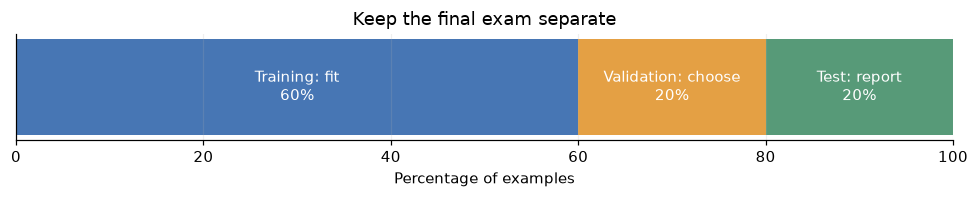

In [2]:
fig, ax = plt.subplots(figsize=(9, 1.9))
for start, size, color, label in [(0, 60, '#4776b4', 'Training: fit\n60%'),
                                 (60, 20, '#e4a044', 'Validation: choose\n20%'),
                                 (80, 20, '#579a78', 'Test: report\n20%')]:
    ax.barh(0, size, left=start, color=color, height=.65)
    ax.text(start + size/2, 0, label, ha='center', va='center', color='white')
ax.set(xlim=(0, 100), yticks=[], xlabel='Percentage of examples', title='Keep the final exam separate')
plt.tight_layout()
plt.show()

## 1.2 A Reproducible Three-Way Split

We will use delivery time as our regression target. Each row describes a separate fictional delivery, with distance and the number of stops as features. The random noise represents things our features cannot explain.

First we hold out 20% for testing. Then we take 25% of the remaining 80% for validation: $0.25 \times 0.80 = 0.20$. This leaves 60% for training. All features and their matching targets must be split together.

The test arrays will be created now, but we will leave them alone until Part 6. Merely naming a set “test” does not protect it: it stays a test set only while it does not influence our choices.

In [3]:
rng = np.random.default_rng(42)
X_reg = pd.DataFrame({'distance_km': rng.uniform(1, 25, 600),
                      'stops': rng.integers(0, 8, 600)})
y_reg = 8 + 2.2 * X_reg['distance_km'] + 3 * X_reg['stops'] + rng.normal(0, 6, 600)
Xr_dev, Xr_test, yr_dev, yr_test = train_test_split(
    X_reg, y_reg, test_size=.20, random_state=42)
Xr_train, Xr_val, yr_train, yr_val = train_test_split(
    Xr_dev, yr_dev, test_size=.25, random_state=42)
display(pd.DataFrame({'set': ['Training', 'Validation', 'Test'],
                      'rows': [len(yr_train), len(yr_val), len(yr_test)]}))

,set,rows
0,Training,360
1,Validation,120
2,Test,120


## 1.3 Data Leakage: Accidentally Seeing the Answers

**Data leakage** occurs when information unavailable at prediction time influences training or selection. It makes evaluation look easier than the real task.

Examples include scaling the entire dataset before splitting, selecting features using all labels, putting copies of one record in different sets, or predicting delivery time using a feature recorded only after arrival. Repeatedly checking test scores while choosing a model also turns the test set into a validation set.

Use a **pipeline** to learn preprocessing only from training data. The scaler's means and standard deviations come from `fit`; validation and test data receive the already learned transformation. Pipelines also keep this boundary intact inside cross-validation.

Random splitting assumes rows are sufficiently independent and representative. For forecasting, train on the past and evaluate on later periods. For repeated observations from the same person or account, keep each group together when the goal is prediction for new groups. Stratification alone does not solve time or group leakage.

In [4]:
reg_model = make_pipeline(StandardScaler(), LinearRegression())
reg_model.fit(Xr_train, yr_train)
r_val_pred = reg_model.predict(Xr_val)
print('The scaler and regression were fitted on training rows only.')

The scaler and regression were fitted on training rows only.


## 1.4 Cross-Validation: Rotate the Practice Exam

One validation split can be lucky or unlucky. In **K-fold cross-validation**, divide the available training data into K folds. Fit on K−1 folds, score on the remaining fold, and rotate until every fold has been held out once. Every fit starts fresh, including its preprocessing.

Here we use five folds inside our training set as a demonstration. We summarize the mean and variation across folds. For classification, stratified folds often help keep class proportions similar. For time series or grouped rows, use an appropriate time or group splitter instead.

Cross-validation can replace a single validation split when selecting hyperparameters. It does **not** make it acceptable to tune on the final test set. Fold-to-fold standard deviation describes variation across these folds; it is not automatically a confidence interval for future performance. Extensive searching can also overfit cross-validation results.

In [5]:
folds = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = -cross_val_score(reg_model, Xr_train, yr_train,
                          cv=folds, scoring='neg_mean_absolute_error')
print('Fold MAEs:', np.round(cv_mae, 2))
print(f'Mean MAE: {cv_mae.mean():.2f} minutes; fold SD: {cv_mae.std():.2f}')
# scikit-learn negates error scorers so that higher scores are always better.
# Negate them again to read ordinary, positive errors.

Fold MAEs: [4.88 5.05 4.92 4.98 4.54]
Mean MAE: 4.88 minutes; fold SD: 0.18


---
# Part 2: Regression Metrics

## 2.1 What Does an Error Mean?

For regression, both the true answer $y_i$ and prediction $\hat y_i$ are numbers. Define a **residual** as $e_i=y_i-\hat y_i$. Positive residuals mean underprediction; negative residuals mean overprediction. We need a way to summarize errors without letting positive and negative values cancel.

| Metric | Formula | Units | Direction |
|---|---|---|---|
| **MAE** | $\frac{1}{n}\sum_i |y_i-\hat y_i|$ | Target units | Lower is better |
| **MSE** | $\frac{1}{n}\sum_i (y_i-\hat y_i)^2$ | Squared target units | Lower is better |
| **RMSE** | $\sqrt{\mathrm{MSE}}$ | Target units | Lower is better |
| **$R^2$** | $1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}$ | Unitless | Higher is better |

**MAE** gives every extra minute the same additional penalty. **MSE** and **RMSE** emphasize large errors through squaring. RMSE returns to minutes, which makes it easier to communicate than minutes squared. None of these tells us whether errors are mostly early or late; inspect residuals too.

## 2.2 A Small Worked Example

Suppose the true delivery times are `[10, 20, 30]` minutes, and predictions are `[12, 18, 36]`. The residuals are `[-2, 2, -6]`.

* MAE = $(2+2+6)/3 \approx 3.33$ minutes.
* MSE = $(4+4+36)/3 \approx 14.67$ minutes squared.
* RMSE = $\sqrt{14.67} \approx 3.83$ minutes.

The six-minute mistake contributes most of the squared error. This matters if a few very late deliveries are much more harmful than many small mistakes. A metric is a choice about what kinds of errors deserve emphasis, so choose it before comparing models.

In [6]:
actual = np.array([10, 20, 30])
predicted = np.array([12, 18, 36])
print(f'MAE:  {mean_absolute_error(actual, predicted):.2f} minutes')
print(f'MSE:  {mean_squared_error(actual, predicted):.2f} minutes squared')
print(f'RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.2f} minutes')

MAE:  3.33 minutes
MSE:  14.67 minutes squared
RMSE: 3.83 minutes


## 2.3 How Should We Read $R^2$?

$R^2$ compares squared prediction error with the error from predicting the **mean of the evaluated targets**. For a nonconstant target, 1 means perfect predictions, 0 means the same squared error as that mean, and a negative value means worse. It is not a percentage of predictions that were correct, and it can be negative on new data.

In a real workflow, our usable baseline must be learned without the evaluation labels. `DummyRegressor(strategy="mean")` predicts the **training** mean. Its validation $R^2$ need not be exactly zero because the training and validation means differ.

Compare models on the same rows and target. An MAE of 5 means something different for five-minute trips than for cross-country shipping. Even $R^2$ depends on the evaluated population: a narrow range of target values can make an otherwise useful prediction task look difficult by this metric.

In [7]:
reg_baseline = DummyRegressor(strategy='mean').fit(Xr_train, yr_train)
def regression_scores(y, pred):
    return {'MAE (min)': mean_absolute_error(y, pred),
            'RMSE (min)': np.sqrt(mean_squared_error(y, pred)),
            'R²': r2_score(y, pred)}
display(pd.DataFrame({
    'Training-mean baseline': regression_scores(yr_val, reg_baseline.predict(Xr_val)),
    'Linear regression': regression_scores(yr_val, r_val_pred)
}).T.round(3))

,MAE (min),RMSE (min),R²
Training-mean baseline,15.284,18.008,-0.001
Linear regression,4.625,5.787,0.897


## 2.4 Look Beyond a Single Score

A summary score compresses many predictions into one number. Plot actual versus predicted values and residuals to see what it hides. Predictions close to the diagonal are accurate. In a residual plot, a curved trend may suggest a missing nonlinear relationship; a widening spread may suggest errors grow with the target or prediction.

Our fictional data were generated with a linear relationship, so a linear model has a suitable form. Real data are less cooperative. Check errors in meaningful slices, such as long versus short deliveries, while remembering that small slices have less stable estimates. Finding a problem on validation data can guide revisions; finding it on test data calls for a new development cycle and fresh evaluation data.

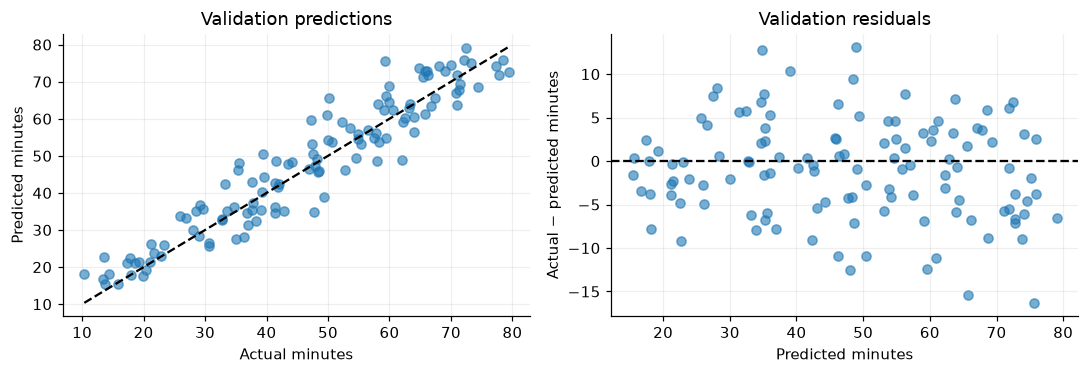

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(yr_val, r_val_pred, alpha=.6)
limits = [min(yr_val.min(), r_val_pred.min()), max(yr_val.max(), r_val_pred.max())]
axes[0].plot(limits, limits, '--', color='black')
axes[0].set(xlabel='Actual minutes', ylabel='Predicted minutes', title='Validation predictions')
axes[1].scatter(r_val_pred, yr_val - r_val_pred, alpha=.6)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Predicted minutes', ylabel='Actual − predicted minutes', title='Validation residuals')
plt.tight_layout()
plt.show()

---
# Part 3: Classification Metrics

## 3.1 Start by Naming the Positive Class

For binary classification, choose which label is **positive**. Positive means “the class we are focusing on,” not necessarily a desirable outcome. In our transaction example, `1` means a transaction truly needs review, and `0` means it does not. The data contain roughly 10% positives.

A probability and a class prediction answer different questions. `predict_proba` returns estimated class probabilities; a decision rule turns them into labels. We will begin with the common threshold of 0.50 and later choose a threshold using validation data.

We stratify both splits to preserve approximately the same class proportions. This reduces the chance that a random split accidentally contains very few positives. It does not create additional examples or guarantee that the data represent future transactions.

In [9]:
X_cls, y_cls = make_classification(
    n_samples=3000, n_features=8, n_informative=5, n_redundant=1,
    weights=[.90, .10], class_sep=1.0, flip_y=.01, random_state=42)
Xc_dev, Xc_test, yc_dev, yc_test = train_test_split(
    X_cls, y_cls, test_size=.20, stratify=y_cls, random_state=42)
Xc_train, Xc_val, yc_train, yc_val = train_test_split(
    Xc_dev, yc_dev, test_size=.25, stratify=yc_dev, random_state=42)
classifier = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
classifier.fit(Xc_train, yc_train)
# Explicitly locate the column for class 1.
pos_column = list(classifier.classes_).index(1)
p_val = classifier.predict_proba(Xc_val)[:, pos_column]
y_val_50 = (p_val >= .50).astype(int)
print(f'Training positive rate: {yc_train.mean():.1%}')
print(f'Validation positive rate: {yc_val.mean():.1%}')

Training positive rate: 10.3%
Validation positive rate: 10.3%


## 3.2 The Confusion Matrix

Every binary prediction falls into one of four boxes:

| Actual / Predicted | Predicted negative (0) | Predicted positive (1) |
|---|---|---|
| **Actual negative (0)** | True negative (TN): correctly leave alone | False positive (FP): unnecessary review |
| **Actual positive (1)** | False negative (FN): miss a needed review | True positive (TP): correctly flag |

A false positive consumes review time; a false negative lets a problematic transaction through. Their consequences may differ considerably. A confusion matrix keeps the counts visible before we compress them into percentages.

**Read the axes carefully.** In scikit-learn, rows are actual labels and columns are predictions. We explicitly pass `labels=[0, 1]` so that the order is clear. Some other tools arrange their matrices differently.

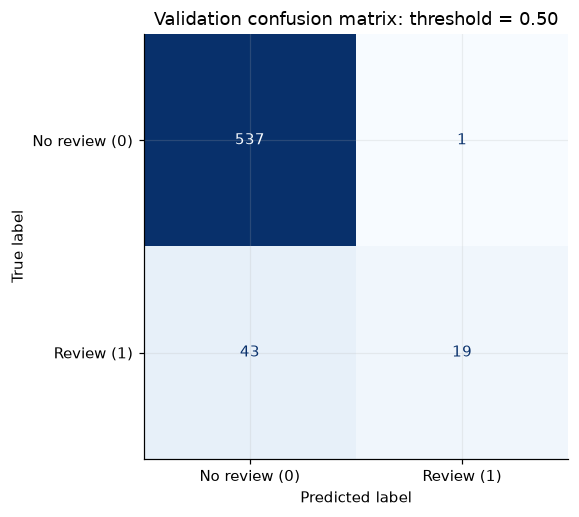

TN=537, FP=1, FN=43, TP=19


In [10]:
cm_val = confusion_matrix(yc_val, y_val_50, labels=[0, 1])
ConfusionMatrixDisplay(cm_val, display_labels=['No review (0)', 'Review (1)']).plot(
    cmap='Blues', colorbar=False)
plt.title('Validation confusion matrix: threshold = 0.50')
plt.tight_layout()
plt.show()
tn, fp, fn, tp = cm_val.ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')

## 3.3 Accuracy, Precision, Recall, and F1

| Metric | Formula | Question it answers |
|---|---|---|
| **Accuracy** | $(TP+TN)/(TP+TN+FP+FN)$ | What fraction of all predictions are correct? |
| **Precision** | $TP/(TP+FP)$ | Of the flagged transactions, how many truly need review? |
| **Recall** | $TP/(TP+FN)$ | Of all transactions needing review, how many did we flag? |
| **F1** | $2TP/(2TP+FP+FN)$ | How well do precision and recall combine? |

High precision means fewer false alarms relative to the number flagged. High recall means fewer missed positives relative to all positives. **Specificity**, $TN/(TN+FP)$, is recall for the negative class.

F1 is the harmonic mean of precision and recall. It is low if either is low, but ignores true negatives and does not directly encode monetary costs or review capacity. No single metric is best for every task.

If a model predicts no positives, precision has a zero denominator. In our code, `zero_division=0` reports zero in that case so the tables remain readable; it does not mean the mathematical ratio was defined.

In [11]:
def classification_scores(y, pred):
    return {'Accuracy': accuracy_score(y, pred),
            'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred, zero_division=0),
            'F1': f1_score(y, pred, zero_division=0),
            'Balanced accuracy': balanced_accuracy_score(y, pred)}
display(pd.Series(classification_scores(yc_val, y_val_50), name='Validation at 0.50').round(3))

Accuracy             0.927
Precision            0.950
Recall               0.306
F1                   0.463
Balanced accuracy    0.652
Name: Validation at 0.50, dtype: float64

## 3.4 Check Your Understanding

A separate fictional sample contains 100 transactions. Ten truly need review. A model flags eight transactions: six correctly and two incorrectly.

Before opening the answer, calculate TP, FP, FN, and TN. Then calculate accuracy, precision, recall, and F1. Which number would tell a reviewer how often a flag is useful? Which would tell us how many problematic transactions we caught?

<details>
<summary>Worked answer</summary>

TP = 6, FP = 2, FN = 4, TN = 88. Accuracy = 94%; precision = 6/8 = 75%; recall = 6/10 = 60%; F1 = 12/18 ≈ 66.7%. Precision describes the usefulness of a flag, while recall describes coverage of actual positives. Both are needed to understand the tradeoff.

</details>

---
# Part 4: Class Imbalance

## 4.1 The Accuracy Trap

Suppose just 1% of transactions need review. Predicting “no review” for every row achieves **99% accuracy**, while catching none of the positives. The high score comes from the class proportions, not useful detection.

Always compare with a simple baseline on the same evaluation rows. `DummyClassifier(strategy="most_frequent")` learns the majority label from training data and always predicts it. Beating that baseline on accuracy is useful context, but it is not enough: inspect positive-class recall and precision as well.

**Balanced accuracy** averages recall across classes. In a binary problem it is $(\text{recall}+\text{specificity})/2$. A majority-only classifier gets 0.50 when both classes are present, regardless of their proportions. This gives both classes equal influence, but still does not describe a particular organization's costs.

In [12]:
cls_baseline = DummyClassifier(strategy='most_frequent').fit(Xc_train, yc_train)
display(pd.DataFrame({
    'Majority baseline': classification_scores(yc_val, cls_baseline.predict(Xc_val)),
    'Logistic regression at 0.50': classification_scores(yc_val, y_val_50)
}).T.round(3))

,Accuracy,Precision,Recall,F1,Balanced accuracy
Majority baseline,0.897,0.00,0.000,0.000,0.500
Logistic regression at 0.50,0.927,0.95,0.306,0.463,0.652


## 4.2 Ranking Quality: ROC-AUC and Average Precision

Sometimes we want to know whether positive examples receive higher scores than negative examples, before choosing a threshold.

**ROC curves** plot true positive rate (recall) against false positive rate, $FP/(FP+TN)$, as the threshold changes. ROC-AUC summarizes the curve. A score of 1 indicates perfect ranking; 0.50 corresponds to random ranking in expectation. A high ROC-AUC does not guarantee high precision at the operating threshold. When negatives are numerous, even a small false positive rate can produce many false alarms.

**Precision–recall curves** show precision versus recall. They focus more directly on detecting the positive class. **Average precision (AP)** summarizes precision at increases in recall; it is not simply the trapezoidal area under the curve. The positive fraction is a useful no-skill precision reference, and AP for uninformative scores is around this level, with finite-sample variation.

Compute these metrics from probabilities or decision scores, not thresholded labels. AP depends on class prevalence, so comparisons across datasets with different positive rates require care.

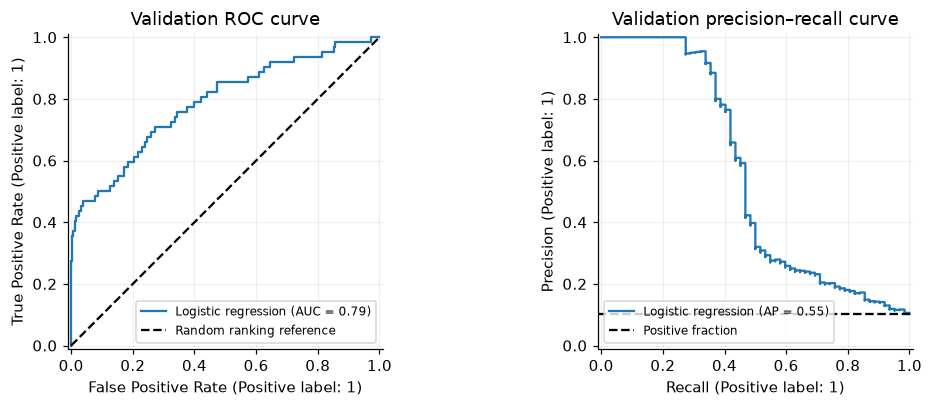

ROC-AUC: 0.787
Average precision: 0.547


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
RocCurveDisplay.from_predictions(yc_val, p_val, ax=axes[0], name='Logistic regression')
axes[0].plot([0, 1], [0, 1], 'k--', label='Random ranking reference')
axes[0].legend(fontsize=8)
PrecisionRecallDisplay.from_predictions(yc_val, p_val, ax=axes[1], name='Logistic regression')
axes[1].axhline(yc_val.mean(), color='black', linestyle='--', label='Positive fraction')
axes[1].legend(fontsize=8)
axes[0].set_title('Validation ROC curve')
axes[1].set_title('Validation precision–recall curve')
plt.tight_layout()
plt.show()
print(f'ROC-AUC: {roc_auc_score(yc_val, p_val):.3f}')
print(f'Average precision: {average_precision_score(yc_val, p_val):.3f}')

## 4.3 What Can We Do About Imbalance?

Start by making sure the evaluation matches the problem: define the positive class, inspect prevalence, use meaningful metrics, and keep evaluation data representative. Changing the model is a separate step.

| Approach | What changes? | Important limitation |
|---|---|---|
| **Class weights** | Training penalizes errors on selected classes more heavily | May change probability calibration and increase false alarms |
| **Resampling** | Training sees more minority or fewer majority examples | Must happen only within training data or each training fold |
| **Threshold adjustment** | The same scores lead to different decisions | Trades off errors; does not improve the underlying ranking |
| **Better data/features** | The model has more useful information | New features must be available at prediction time |

Do not oversample before splitting: duplicate or closely related examples could appear in training and evaluation. Do not “balance” the test set merely to improve a score; precision should be assessed under the intended class mix.

For multiclass tasks, report per-class results. **Macro** averaging weights classes equally; **weighted** averaging weights them by their support and can hide weak minority performance. Our examples use binary metrics with `1` as the positive class.

---
# Part 5: Probabilities, Thresholds, and Decisions

## 5.1 A Threshold Is a Choice

A classifier might estimate a 0.30 probability that a transaction needs review. Whether we flag it depends on our decision rule:

$$\hat y = 1 \quad \text{if} \quad p(y=1\mid X) \ge t.$$

At $t=0.50$ it is negative; at $t=0.20$ it is positive. The fitted model and probability have not changed.

Lowering the threshold flags at least as many examples, so recall cannot decrease on a fixed dataset. False positives cannot decrease either. Precision often falls as more weak candidates are admitted, but it need not change monotonically in a finite sample.

Choose the metric, constraint, or cost rule before searching thresholds. A team with limited review capacity may prefer precision at a feasible workload; another may prioritize recall. **0.50 is a common default, not a universal optimum.**

In [14]:
def threshold_scores(y, probabilities, threshold):
    labels = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, labels, labels=[0, 1]).ravel()
    return {'Threshold': float(threshold), **classification_scores(y, labels),
            'Flagged': int(labels.sum()), 'FP': int(fp), 'FN': int(fn)}
comparison = pd.DataFrame([threshold_scores(yc_val, p_val, t) for t in [.10, .25, .50, .75]])
display(comparison.round(3))

,Threshold,Accuracy,Precision,Recall,F1,Balanced accuracy,Flagged,FP,FN
0,0.10,0.757,0.241,0.629,0.348,0.700,162,123,23
1,0.25,0.912,0.600,0.435,0.505,0.701,45,18,35
2,0.50,0.927,0.950,0.306,0.463,0.652,20,1,43
3,0.75,0.907,1.000,0.097,0.176,0.548,6,0,56


## 5.2 Choose on Validation Data

For this teaching example, decide in advance that each missed positive costs **5 units** and each unnecessary review costs **1 unit**. Correct predictions cost zero. These are fictional costs chosen to illustrate the calculation, not a policy recommendation.

$$\text{Validation cost} = 5\times FN + 1\times FP.$$

We will search a predeclared grid from 0 to 1 in steps of 0.01, choose the threshold with the lowest validation cost, and break ties by choosing the higher threshold to reduce workload. The chosen value is best only among these grid values on this validation sample.

The validation minimum is optimistic because we used these rows to make a choice. We need an untouched test set to assess that choice. With few positives, threshold estimates can be unstable; cross-validation within development data can help, but does not remove the need for honest final evaluation.

Chosen validation threshold: 0.24


,Chosen rule
Threshold,0.240000
Precision,0.580000
Recall,0.467742
Flagged,50.000000
FP,21.000000
FN,33.000000
Cost,186.000000


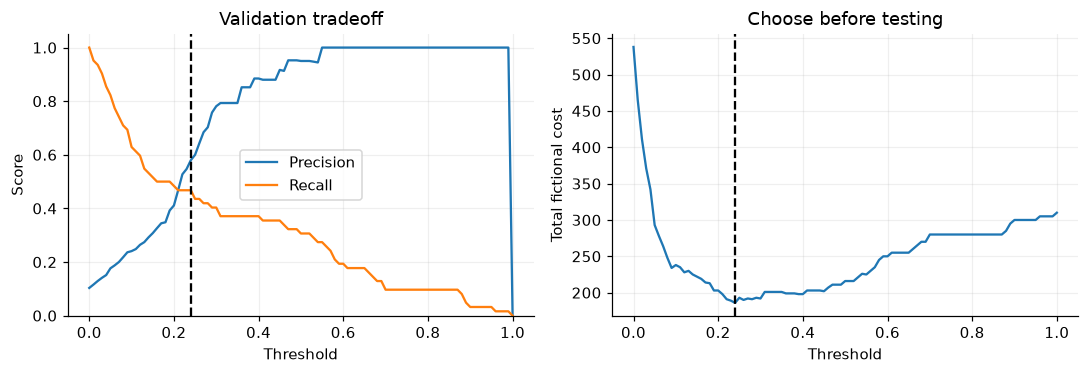

In [15]:
FN_COST, FP_COST = 5, 1
threshold_grid = np.linspace(0, 1, 101)
threshold_table = pd.DataFrame([
    threshold_scores(yc_val, p_val, t) for t in threshold_grid])
threshold_table['Cost'] = FN_COST * threshold_table['FN'] + FP_COST * threshold_table['FP']
best_row = threshold_table.sort_values(['Cost', 'Threshold'], ascending=[True, False]).iloc[0]
chosen_threshold = float(best_row['Threshold'])
print(f'Chosen validation threshold: {chosen_threshold:.2f}')
display(best_row[['Threshold', 'Precision', 'Recall', 'Flagged', 'FP', 'FN', 'Cost']].to_frame('Chosen rule'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(threshold_table['Threshold'], threshold_table['Precision'], label='Precision')
axes[0].plot(threshold_table['Threshold'], threshold_table['Recall'], label='Recall')
axes[0].set(xlabel='Threshold', ylabel='Score', ylim=(0, 1.05), title='Validation tradeoff')
axes[0].legend()
axes[1].plot(threshold_table['Threshold'], threshold_table['Cost'])
axes[1].set(xlabel='Threshold', ylabel='Total fictional cost', title='Choose before testing')
for ax in axes:
    ax.axvline(chosen_threshold, color='black', linestyle='--')
plt.tight_layout()
plt.show()

## 5.3 Good Ranking Does Not Guarantee Good Probabilities

A model's score of 0.80 should not automatically be read as an 80% real-world risk. A model is **calibrated** if, among examples given probabilities near 0.80, approximately 80% are positive. A model can rank examples well while being overconfident or underconfident.

**Log loss** evaluates probability predictions, penalizing confident incorrect predictions strongly. Lower is better. It measures more than calibration alone, so a single log-loss number cannot establish that probabilities are calibrated. Calibration curves provide another useful check.

If probabilities were calibrated and the only consequences were the two constant error costs above, the theoretical threshold would be $C_{FP}/(C_{FP}+C_{FN})=1/6$. Our empirical validation choice can differ because probabilities are imperfect, the sample is finite, and the grid is discrete. We do not replace the validation choice after seeing test results.

Any fitted calibration method must also respect data boundaries. Fit it using held-out development predictions or suitable cross-validation, never on the final test set.

In [16]:
print(f'Validation log loss: {log_loss(yc_val, p_val):.3f}')
print(f'Cost-based threshold under calibrated probabilities: {FP_COST / (FP_COST + FN_COST):.3f}')

Validation log loss: 0.256
Cost-based threshold under calibrated probabilities: 0.167


---
# Part 6: Putting It Together

## 6.1 Freeze the Decisions, Then Open the Test Set

We have now fixed the features, preprocessing, model types, and classification threshold. For clarity, we keep the models fitted on training data; we do not refit before this demonstration's final evaluation. That keeps the selected threshold attached to the same fitted classifier that produced the validation scores.

In another workflow, one might refit on all development data, but that can change the score distribution and requires a deliberate threshold-selection procedure. It should be planned before the test is opened.

The following cell is the first place we predict or score on test data. We report the predefined primary metrics, baseline context, and the chosen threshold. We also show 0.50 as a prespecified reference, not as another threshold to select using the test set. If the reference happens to perform better, report that result honestly and leave the chosen rule unchanged.

In [17]:
r_test_pred = reg_model.predict(Xr_test)
display(pd.DataFrame({
    'Training-mean baseline': regression_scores(yr_test, reg_baseline.predict(Xr_test)),
    'Linear regression': regression_scores(yr_test, r_test_pred)
}).T.round(3))
p_test = classifier.predict_proba(Xc_test)[:, pos_column]
final_rows = []
for label, threshold in [('Prespecified reference', .50), ('Validation-selected rule', chosen_threshold)]:
    row = threshold_scores(yc_test, p_test, threshold)
    row['Rule'] = label
    row['Cost per transaction'] = (FN_COST * row['FN'] + FP_COST * row['FP']) / len(yc_test)
    final_rows.append(row)
display(pd.DataFrame(final_rows).set_index('Rule').round(3))
print(f'Test ROC-AUC: {roc_auc_score(yc_test, p_test):.3f}')
print(f'Test average precision: {average_precision_score(yc_test, p_test):.3f}')
print('Evaluation complete. Do not tune the rule using these test results.')

,MAE (min),RMSE (min),R²
Training-mean baseline,14.177,17.422,-0.013
Linear regression,4.756,6.360,0.865


,Threshold,Accuracy,Precision,Recall,F1,Balanced accuracy,Flagged,FP,FN,Cost per transaction
Rule,,,,,,,,,,
Prespecified reference,0.50,0.928,1.00,0.306,0.469,0.653,19,0,43,0.358
Validation-selected rule,0.24,0.910,0.58,0.468,0.518,0.714,50,21,33,0.310


Test ROC-AUC: 0.786
Test average precision: 0.565
Evaluation complete. Do not tune the rule using these test results.


## 6.2 What Should We Report?

A useful evaluation report says what was predicted, which population the rows represent, how the data were split, which metric drove selection, and how the final rule performed. Include counts and class prevalence alongside percentages so readers can judge how much evidence supports them.

An observed score is an estimate, not a promise. A test set with a small number of positives can produce a noisy recall estimate. A random seed makes an experiment reproducible; it does not make the result certain. Confidence intervals or repeated development evaluations can provide more context when decisions require it.

A held-out test set also cannot establish performance after the world changes. Review policies, class prevalence, and feature distributions can shift. Once a model is used, monitor meaningful outcomes and revisit evaluation with fresh labeled data.

For this notebook, the correct conclusion is limited: these methods work on two synthetic examples. The datasets do not establish usefulness for an actual delivery company or review team.

---
# Practice: Explain the Evaluation

Try answering these questions before expanding the notes. The code experiments use validation data; keep the completed test evaluation fixed.

1. A model has much lower training MAE than validation MAE. What might explain the gap, and what would you check next?
2. Two models have the same MAE, but one has much higher RMSE. What does that suggest about its errors?
3. A model gets 98% accuracy when 2% of examples are positive. What baseline and additional metrics do you need?
4. A reviewer can inspect only 20 transactions per day. Why might maximizing F1 be insufficient?
5. Try changing `FN_COST` to 10 in a **copy of the validation threshold-search cell**. Does the chosen threshold change? Why should this experiment not lead to revising the reported test rule?
6. Why is fitting a scaler on all rows before cross-validation a form of leakage, even though the scaler does not use labels?

<details>
<summary>Discussion notes</summary>

1. Overfitting is one possibility; also check distribution differences, leakage, and whether the sample is representative. Compare with simpler models using development data.
2. Its mistakes are likely more uneven, with larger errors receiving extra weight under squaring. Inspect the residual distribution.
3. An always-negative baseline also gets 98% accuracy. Inspect the confusion matrix, positive recall and precision, balanced accuracy, and precision–recall behavior.
4. F1 does not enforce a workload limit. Examine the number flagged and precision/recall at feasible operating points; a top-k policy is another possible decision rule.
5. Higher missed-positive cost can favor a lower threshold, although the selected grid value need not change. A new policy needs a new evaluation plan, not repeated tuning against this test set.
6. Held-out feature values influence the learned means and variances. Fit the scaler inside each training fold using a pipeline.

</details>

---
# Chapter Summary

| Idea | Takeaway |
|---|---|
| **Train / validation / test** | Learn on training data, choose on validation data, report on untouched test data |
| **Leakage** | Keep preprocessing, feature selection, and resampling inside the training boundary |
| **Regression** | MAE measures typical absolute error; RMSE emphasizes larger mistakes; $R^2$ compares squared error with a mean reference |
| **Classification** | Confusion counts explain accuracy, precision, recall, and F1 |
| **Imbalance** | High accuracy can hide complete failure on the positive class; compare with baselines |
| **Ranking** | ROC-AUC and AP describe score ordering across thresholds, with different perspectives |
| **Thresholds** | Choose a decision rule using development data and the actual goal or costs |
| **Final evaluation** | Report the frozen rule honestly and explain the limits of the evidence |

A useful model evaluation connects three things: **an honest data split, a metric that reflects the task, and a decision rule that fits the consequences.**

### References and Further Reading

This chapter follows the welcoming, section-based lesson format of the [DSS DeCal updated textbook](https://github.com/dssdecal/updatedtextbook), particularly its ML Foundations, Supervised Learning, and ML & Modeling II notebooks. Explanations and examples here are newly written.

For implementation details, consult the scikit-learn guides on [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html), [decision threshold tuning](https://scikit-learn.org/stable/modules/classification_threshold.html), and [data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).